# Credit Portfolio Segmentation and Risk Pattern Analysis
**Unsupervised learning on Lending Club loans** (K-Means, Hierarchical clustering, DBSCAN, PCA, t-SNE, UMAP)

**Goal:** group borrowers with similar financial and credit characteristics, then compare how each group repaid historically.

**Important rule:** the `Default` column is *never* used to build the clusters. It is only used afterwards to compare outcomes.

**Notebook outline**
1. Setup and loading data
2. Data cleaning
3. Feature engineering
4. Exploratory data analysis (EDA)
5. Scaling, encoding and PCA
6. Clustering: choosing k, K-Means, Hierarchical, DBSCAN, comparison
7. Dimensionality reduction maps (PCA, t-SNE, UMAP)
8. Cluster profiling
9. Default pattern analysis
10. Anomaly detection
11. Save the model and conclusions

> Run this notebook from the project root folder (the one that contains `data/raw/`). Total run time is about 10 minutes.

## 1. Setup and loading data

In [1]:
import warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
import umap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200, "display.max_columns", 40)

RANDOM_STATE = 42          # same seed everywhere -> reproducible results
DATA_PATH = "data/raw/loans_granting_model_dataset.csv"
SAMPLE_SIZE = 10_000       # sample for the slow methods (hierarchical, DBSCAN, t-SNE, UMAP)
K_FINAL = 5                # chosen in section 6.1

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", raw.shape)
raw.head()

Shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [3]:
# Data understanding: type, missing values and unique values of every column
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "unique": raw.nunique(),
})
audit

,dtype,missing,missing_pct,unique
id,int64,0,0.00,1347681
issue_d,str,0,0.00,139
revenue,float64,0,0.00,65608
dti_n,float64,0,0.00,7068
loan_amnt,int64,0,0.00,1560
fico_n,float64,0,0.00,48
experience_c,int64,0,0.00,2
emp_length,str,0,0.00,12
purpose,str,0,0.00,14
home_ownership_n,str,0,0.00,4


**What we see:** 1,347,681 loans and 15 columns. `desc` is 91% empty, `title` is almost a copy of `purpose`, `experience_c` is nearly constant, and `zip_code` has about 945 values. `Default` is the 0/1 outcome (about 20% defaulted).

## 2. Data cleaning

In [4]:
df = raw.copy()
log = []                       # we record every cleaning step
n0 = len(df)

# 2.1 duplicates
df = df.drop_duplicates()
log.append(("Exact duplicate rows removed", n0 - len(df)))
n = len(df)
df = df.drop_duplicates(subset="id")
log.append(("Repeated loan ids removed", n - len(df)))

# 2.2 drop columns that are identifiers, mostly empty, duplicated or constant
drop_cols = ["id", "desc", "title", "zip_code", "experience_c"]
df = df.drop(columns=drop_cols)
log.append(("Columns dropped", len(drop_cols)))

# 2.3 make text values consistent
df["purpose"] = df["purpose"].str.strip().str.lower()
df["home_ownership_n"] = df["home_ownership_n"].str.strip().str.upper()
df["addr_state"] = df["addr_state"].str.strip().str.upper()
df["emp_length"] = df["emp_length"].str.strip()

# 2.4 home ownership 'OTHER' is tiny (0.04%) and ambiguous
n = len(df)
df = df[df["home_ownership_n"].isin(["MORTGAGE", "RENT", "OWN"])]
log.append(("Rows with home ownership 'OTHER' removed", n - len(df)))

# 2.5 impossible debt-to-income values (999 is a placeholder)
n = len(df)
df = df[(df["dti_n"] >= 0) & (df["dti_n"] <= 100)]
log.append(("Rows with dti > 100 removed", n - len(df)))

# 2.6 any remaining missing values in key columns
key_cols = ["revenue", "dti_n", "loan_amnt", "fico_n", "purpose",
            "home_ownership_n", "addr_state", "Default"]
n = len(df)
df = df.dropna(subset=key_cols)
log.append(("Rows with missing key values removed", n - len(df)))
pd.DataFrame(log, columns=["step", "rows_affected"])

,step,rows_affected
0,Exact duplicate rows removed,0
1,Repeated loan ids removed,0
2,Columns dropped,5
3,Rows with home ownership 'OTHER' removed,517
4,Rows with dti > 100 removed,532
5,Rows with missing key values removed,0


In [5]:
# 2.7 dates -> time features (used for trends, NOT for clustering)
df["issue_date"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
df["issue_year"] = df["issue_date"].dt.year
df["issue_month"] = df["issue_date"].dt.month
df = df.drop(columns=["issue_d"])

# 2.8 employment length: text -> years. 'NI' means "no information" -> missing
EMP_MAP = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
           "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
           "10+ years": 10}
df["emp_years"] = df["emp_length"].map(EMP_MAP)
df["emp_info_missing"] = df["emp_years"].isna().astype(int)
print("Employment 'NI' rows:", df["emp_info_missing"].sum())

# 2.9 US region from state (for the geographic analysis)
REGIONS = {"Northeast": "CT ME MA NH RI VT NJ NY PA",
           "Midwest": "IL IN MI OH WI IA KS MN MO NE ND SD",
           "South": "DE FL GA MD NC SC VA DC WV AL KY MS TN AR LA OK TX",
           "West": "AZ CO ID MT NV NM UT WY AK CA HI OR WA"}
STATE_REGION = {s: r for r, states in REGIONS.items() for s in states.split()}
df["region"] = df["addr_state"].map(STATE_REGION)

df = df.reset_index(drop=True)
print("Clean data:", df.shape, "| overall default rate: %.2f%%" % (df["Default"].mean() * 100))
del raw   # free memory

Employment 'NI' rows: 77906
Clean data: (1346632, 15) | overall default rate: 19.98%


## 3. Feature engineering

* **log(1 + income)** - income is strongly right-skewed, the log makes it more symmetric
* **loan_to_income** = loan amount / income (a simple affordability measure)
* **Outliers** - income, DTI and loan-to-income are capped at their 99.5th percentile (winsorising)
* **emp_years** - 'NI' filled with the median
* **purpose_group** - 13 purposes grouped into 4 so one-hot encoding stays small

In [6]:
CAP_Q = 0.995
caps = {
    "revenue": float(df["revenue"].quantile(CAP_Q)),
    "dti_n": float(df["dti_n"].quantile(CAP_Q)),
    "loan_to_income": float((df["loan_amnt"] / df["revenue"]).quantile(CAP_Q)),
    "emp_years_median": float(df["emp_years"].median()),
}
print(caps)

def engineer_features(data, caps):
    """Create the model-ready columns (works for one borrower or the whole table)."""
    out = data.copy()
    out["log_income"] = np.log1p(out["revenue"].clip(upper=caps["revenue"]))
    out["dti_n"] = out["dti_n"].clip(upper=caps["dti_n"])
    out["loan_to_income"] = (out["loan_amnt"] / out["revenue"]).clip(upper=caps["loan_to_income"])
    out["emp_years"] = out["emp_years"].fillna(caps["emp_years_median"])
    out["purpose_group"] = np.where(
        out["purpose"].isin(["debt_consolidation", "credit_card", "home_improvement"]),
        out["purpose"], "other")
    return out

df = engineer_features(df, caps)
df[["revenue", "log_income", "dti_n", "loan_amnt", "fico_n", "emp_years",
    "loan_to_income", "purpose_group", "home_ownership_n"]].head()

{'revenue': 325000.0, 'dti_n': 39.88, 'loan_to_income': 0.5, 'emp_years_median': 6.0}


,revenue,log_income,dti_n,loan_amnt,fico_n,emp_years,loan_to_income,purpose_group,home_ownership_n
0,55000.0,10.915107,5.91,3600,677.0,10.0,0.065455,debt_consolidation,MORTGAGE
1,65000.0,11.082158,16.06,24700,717.0,10.0,0.380000,other,MORTGAGE
2,71000.0,11.170449,13.85,20000,697.0,10.0,0.281690,home_improvement,MORTGAGE
3,104433.0,11.556311,25.37,10400,697.0,3.0,0.099585,other,MORTGAGE
4,34000.0,10.434145,10.20,11950,692.0,4.0,0.351471,debt_consolidation,RENT


## 4. Exploratory Data Analysis (EDA)

In [7]:
num_cols = ["revenue", "dti_n", "loan_amnt", "fico_n", "emp_years", "loan_to_income"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
revenue,1346632.0,77353.69,70360.80,1896.0,46560.00,65000.00,92000.00,10999200.00
dti_n,1346632.0,18.15,8.46,0.0,11.81,17.63,24.06,39.88
loan_amnt,1346632.0,14406.60,8713.86,500.0,7975.00,12000.00,20000.00,40000.00
fico_n,1346632.0,698.16,31.85,612.0,672.00,692.00,712.00,847.50
emp_years,1346632.0,5.97,3.58,0.0,3.00,6.00,10.00,10.00
loan_to_income,1346632.0,0.21,0.11,0.0,0.12,0.20,0.29,0.50


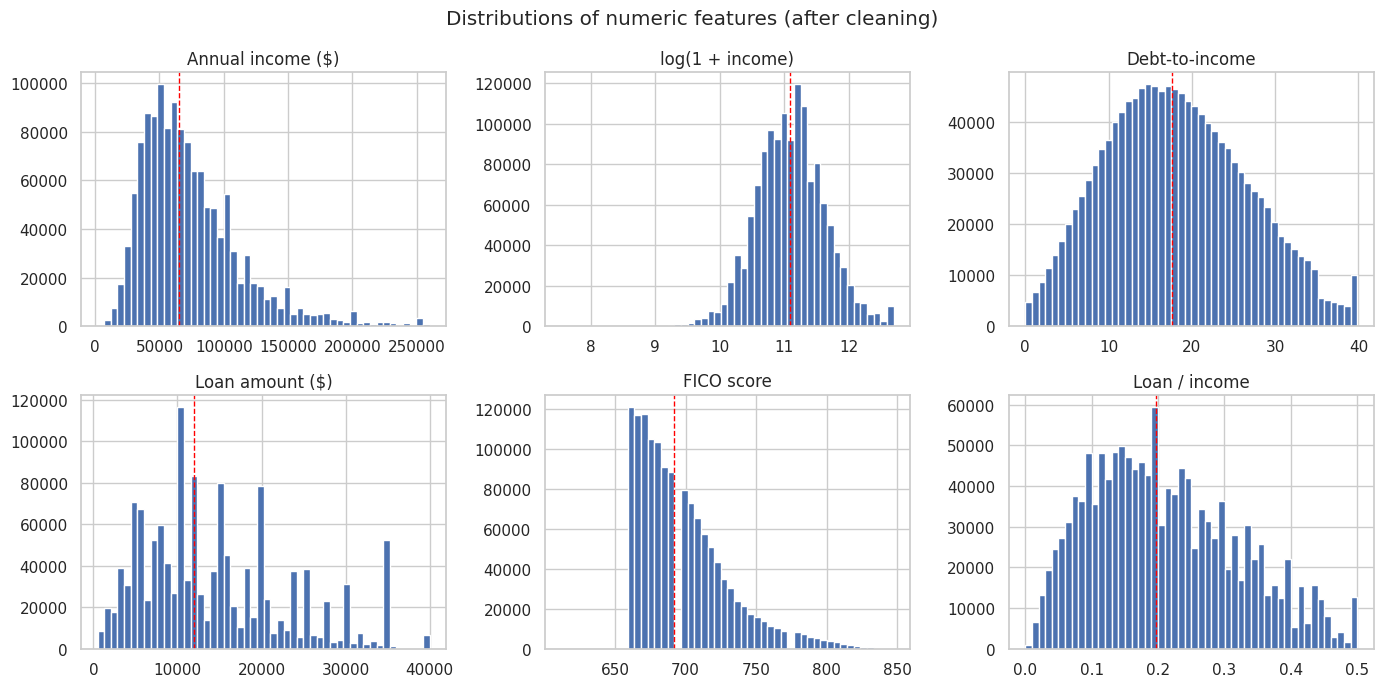

In [8]:
# 4.1 distributions of the numeric features
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
items = [("revenue", "Annual income ($)"), ("log_income", "log(1 + income)"),
         ("dti_n", "Debt-to-income"), ("loan_amnt", "Loan amount ($)"),
         ("fico_n", "FICO score"), ("loan_to_income", "Loan / income")]
for ax, (col, label) in zip(axes.ravel(), items):
    data = df[col]
    if col == "revenue":                       # show up to the 99th percentile only
        data = data[data <= data.quantile(0.99)]
    ax.hist(data, bins=50, color="#4C72B0", edgecolor="white")
    ax.axvline(data.median(), color="red", ls="--", lw=1)
    ax.set_title(label)
plt.suptitle("Distributions of numeric features (after cleaning)")
plt.tight_layout(); plt.show()

Income is strongly right-skewed (median $65,000 but mean $77,354) - that is why we use the log. FICO is roughly bell-shaped around 692.

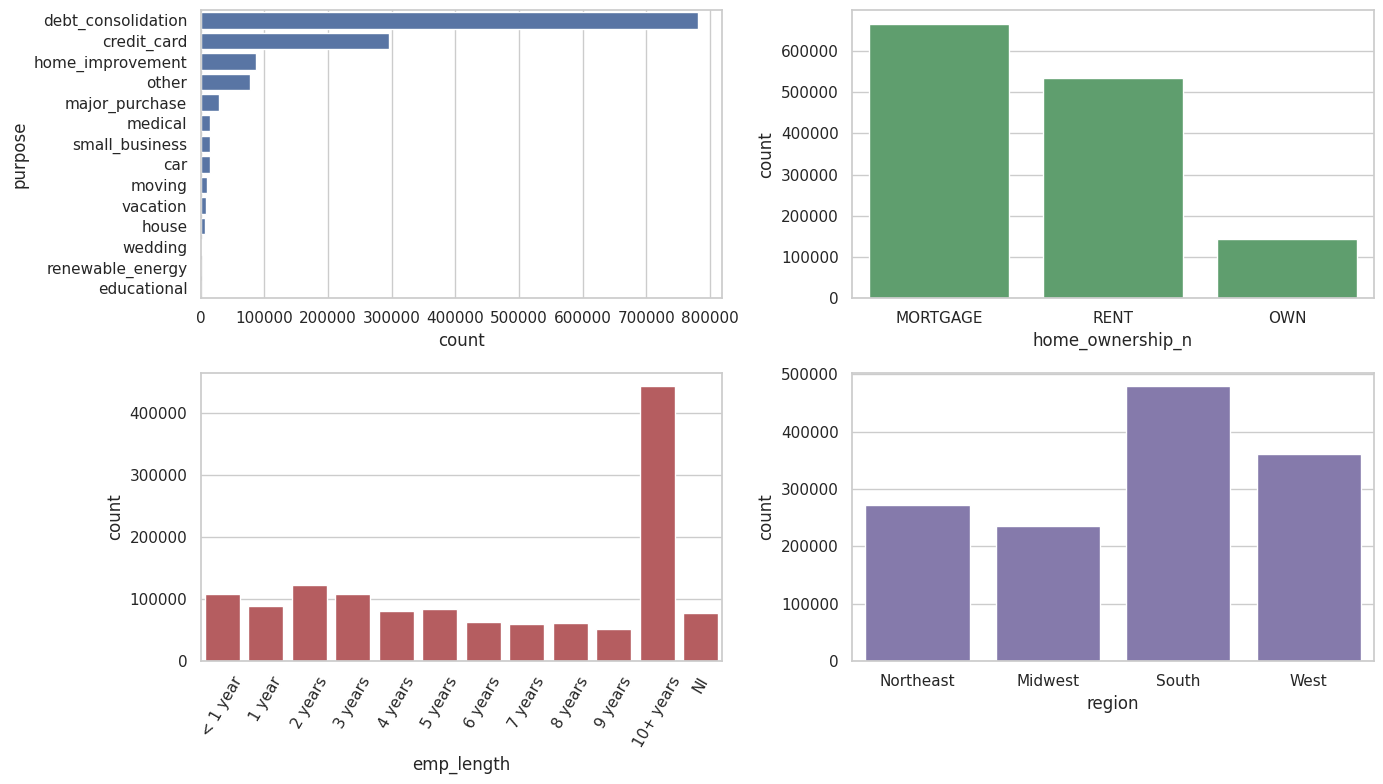

In [9]:
# 4.2 categorical features
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sns.countplot(y="purpose", data=df, order=df["purpose"].value_counts().index, ax=axes[0, 0], color="#4C72B0")
sns.countplot(x="home_ownership_n", data=df, ax=axes[0, 1], color="#55A868")
emp_order = ["< 1 year"] + ["1 year"] + [f"{i} years" for i in range(2, 10)] + ["10+ years", "NI"]
sns.countplot(x="emp_length", data=df, order=emp_order, ax=axes[1, 0], color="#C44E52")
axes[1, 0].tick_params(axis="x", rotation=60)
sns.countplot(x="region", data=df, ax=axes[1, 1], color="#8172B3")
plt.tight_layout(); plt.show()

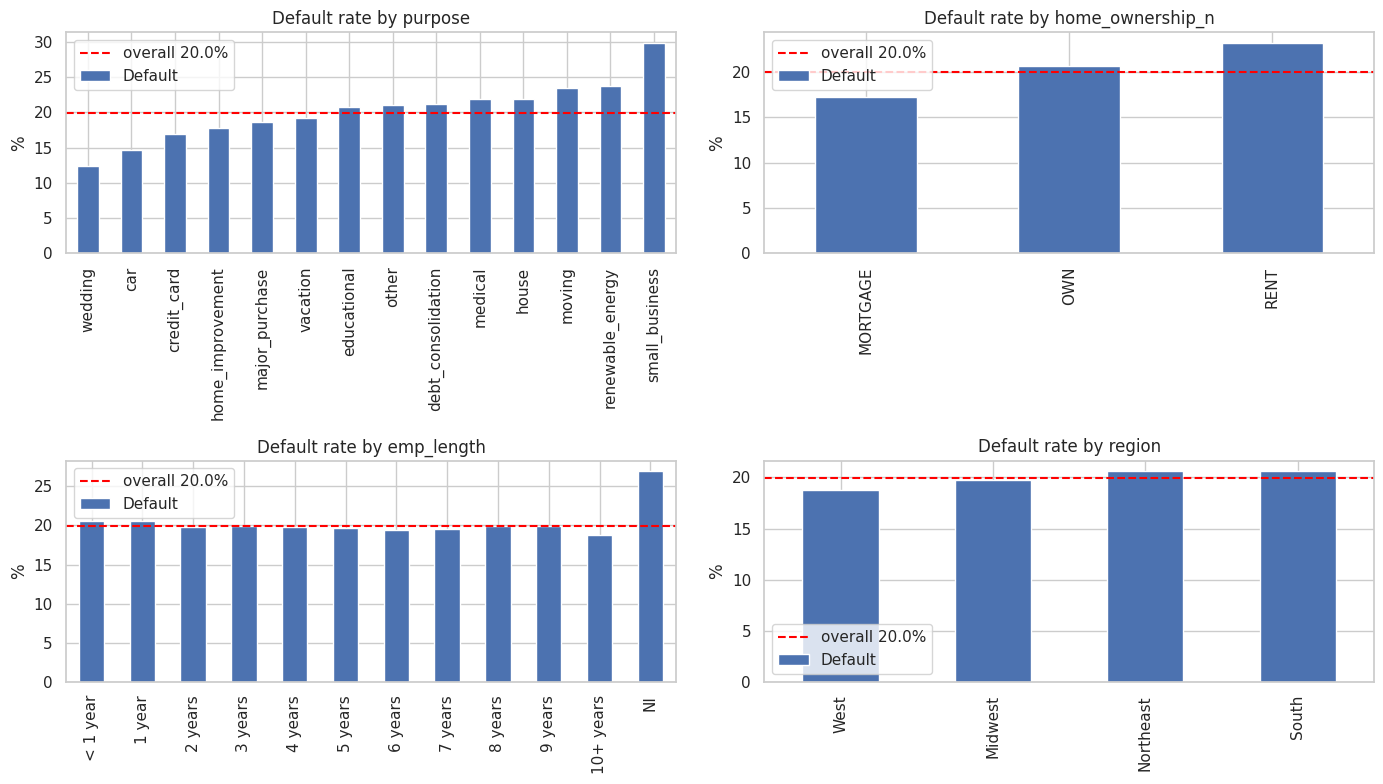

In [10]:
# 4.3 default rate by category (EDA only - Default is NOT a clustering feature)
overall = df["Default"].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col, order in [(axes[0, 0], "purpose", None), (axes[0, 1], "home_ownership_n", None),
                       (axes[1, 0], "emp_length", emp_order), (axes[1, 1], "region", None)]:
    rate = df.groupby(col)["Default"].mean() * 100
    rate = rate.reindex(order) if order else rate.sort_values()
    rate.plot.bar(ax=ax, color="#4C72B0")
    ax.axhline(overall, color="red", ls="--", label=f"overall {overall:.1f}%")
    ax.set_title(f"Default rate by {col}"); ax.set_ylabel("%"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()

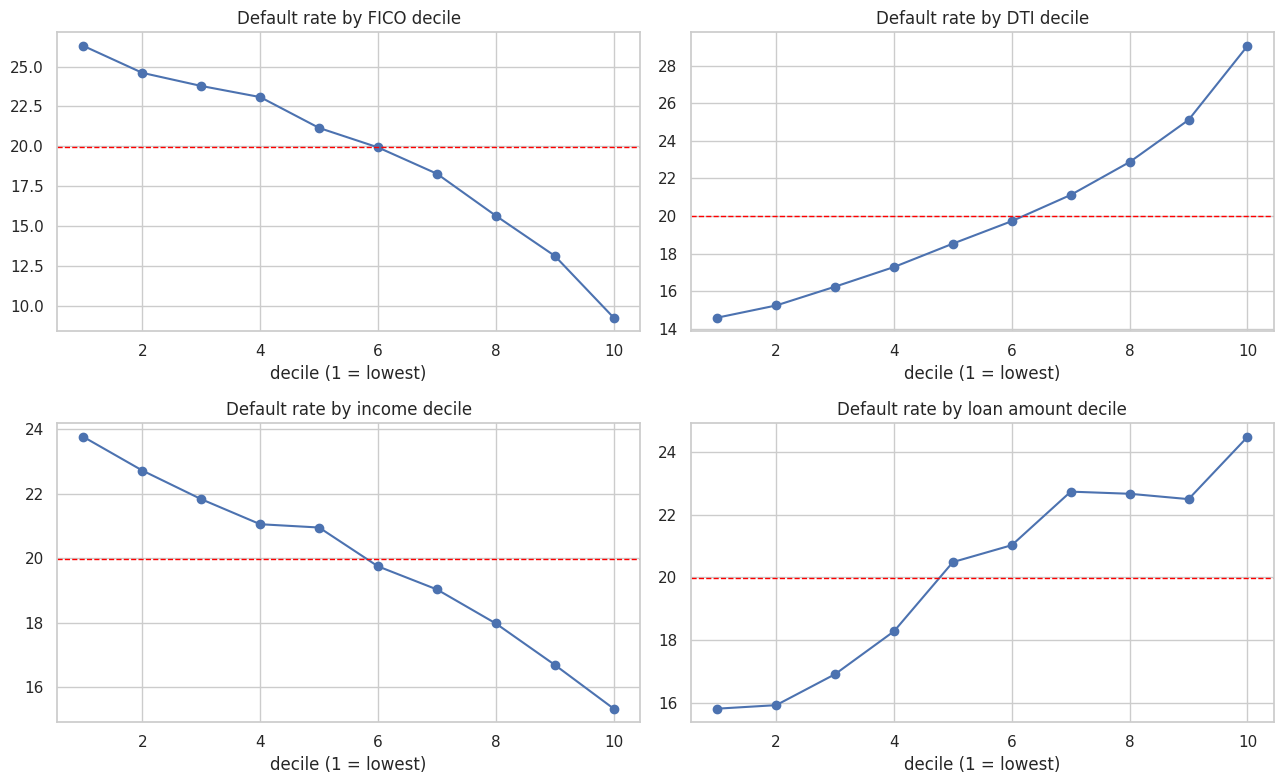

In [11]:
# 4.4 default rate by decile of each numeric variable
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, label) in zip(axes.ravel(), [("fico_n", "FICO"), ("dti_n", "DTI"),
                                           ("revenue", "income"), ("loan_amnt", "loan amount")]):
    rate = df.groupby(pd.qcut(df[col], 10, duplicates="drop"), observed=True)["Default"].mean() * 100
    ax.plot(range(1, len(rate) + 1), rate.values, marker="o")
    ax.axhline(overall, color="red", ls="--", lw=1)
    ax.set_title(f"Default rate by {label} decile"); ax.set_xlabel("decile (1 = lowest)")
plt.tight_layout(); plt.show()

**EDA findings**
* Lowest FICO decile defaults at 26.3%, highest at 9.2%. Highest DTI decile 29.1% vs 14.6% in the lowest.
* Renters default more (23.2%) than mortgage holders (17.2%); small-business loans are the riskiest purpose (29.9%).
* Employment 'NI' (no information) loans default at 27.0%.

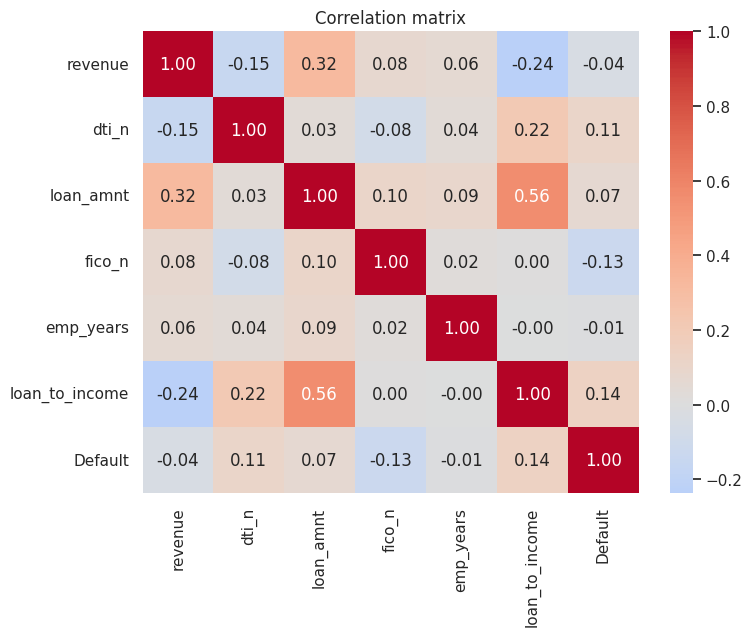

In [12]:
# 4.5 correlation (Default included for EDA only)
corr = df[num_cols + ["Default"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

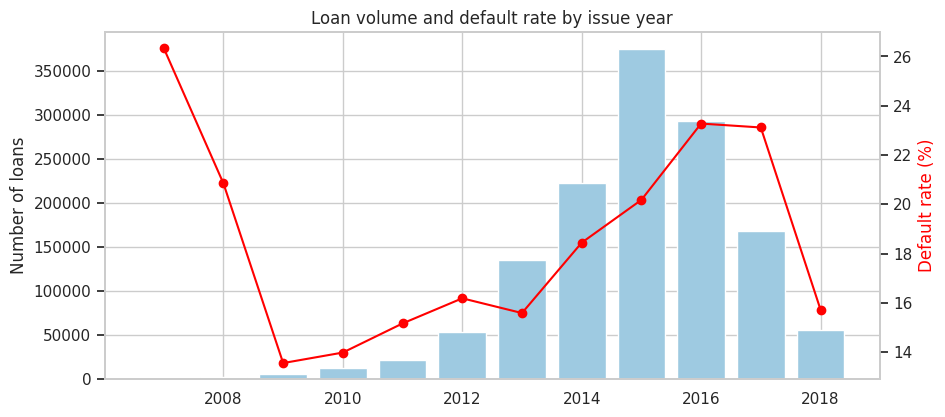

issue_year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
loans,596.00,2345.00,5196.00,12534.00,21720.00,53279.00,134804.0,223101.00,375533.00,292916.00,168632.00,55976.00
default_rate,26.34,20.85,13.57,13.99,15.17,16.19,15.6,18.45,20.19,23.28,23.12,15.74


In [13]:
# 4.6 trend by issue year
yearly = df.groupby("issue_year").agg(loans=("Default", "size"), default_rate=("Default", "mean"))
yearly["default_rate"] *= 100
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(yearly.index, yearly["loans"], color="#9ecae1"); ax1.set_ylabel("Number of loans")
ax2 = ax1.twinx(); ax2.plot(yearly.index, yearly["default_rate"], color="red", marker="o")
ax2.set_ylabel("Default rate (%)", color="red"); ax2.grid(False)
plt.title("Loan volume and default rate by issue year"); plt.show()
yearly.round(2).T

Loans from 2018 look safer only because many have not had time to default yet (they are not 'seasoned').

## 5. Scaling, encoding and PCA

* Numeric features -> `StandardScaler` (mean 0, std 1) so that income in dollars does not dominate FICO.
* Categorical features -> one-hot encoding.
* `Default`, ids, state and dates are **not** clustering features.
* PCA keeps the components that explain at least 90% of the variance.

In [14]:
NUMERIC_FEATURES = ["log_income", "dti_n", "loan_amnt", "fico_n", "emp_years", "loan_to_income"]
CATEGORICAL_FEATURES = ["purpose_group", "home_ownership_n"]
feature_cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES
assert "Default" not in feature_cols          # Default must never be a clustering feature

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
])
X = preprocessor.fit_transform(df[feature_cols])
print("Model matrix:", X.shape)
print(list(preprocessor.get_feature_names_out()))

Model matrix: (1346632, 13)
['num__log_income', 'num__dti_n', 'num__loan_amnt', 'num__fico_n', 'num__emp_years', 'num__loan_to_income', 'cat__purpose_group_credit_card', 'cat__purpose_group_debt_consolidation', 'cat__purpose_group_home_improvement', 'cat__purpose_group_other', 'cat__home_ownership_n_MORTGAGE', 'cat__home_ownership_n_OWN', 'cat__home_ownership_n_RENT']


Components needed for 90% variance: 7 (explains 94.0%)


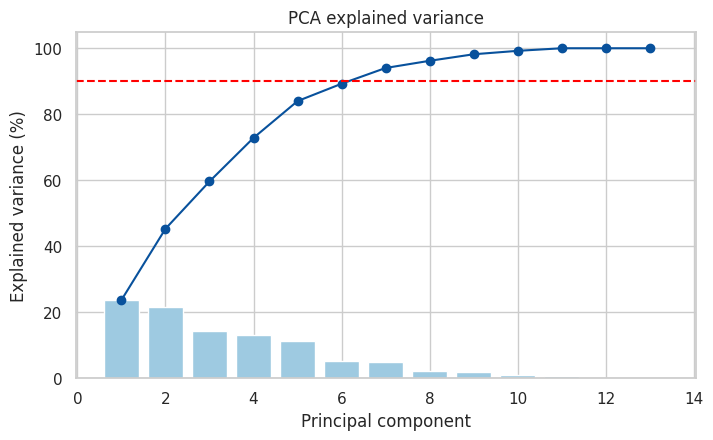

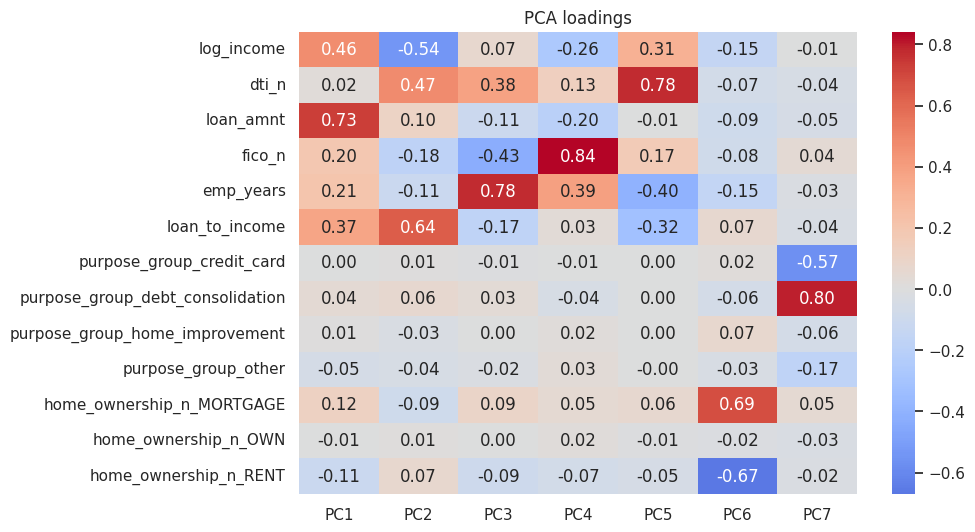

In [15]:
# PCA: fit all components first to look at the explained variance
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_keep = int(np.searchsorted(cum, 0.90) + 1)
print(f"Components needed for 90% variance: {n_keep} (explains {cum[n_keep-1]:.1%})")

plt.figure(figsize=(8, 4.5))
plt.bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_ * 100, color="#9ecae1")
plt.plot(range(1, len(cum) + 1), cum * 100, marker="o", color="#08519c")
plt.axhline(90, color="red", ls="--"); plt.xlabel("Principal component"); plt.ylabel("Explained variance (%)")
plt.title("PCA explained variance"); plt.show()

pca = PCA(n_components=n_keep, random_state=RANDOM_STATE).fit(X)
Z = pca.transform(X)                      # data used for clustering
names = [n.split("__")[1] for n in preprocessor.get_feature_names_out()]
loadings = pd.DataFrame(pca.components_.T, index=names, columns=[f"PC{i+1}" for i in range(n_keep)])
plt.figure(figsize=(9, 6)); sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings"); plt.show()

## 6. Clustering

Hierarchical clustering and DBSCAN are slow on 1.3 million rows, so we take a **random sample of 10,000 borrowers** for the algorithm comparison. The final K-Means is fitted on **all** borrowers.

In [16]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(df), SAMPLE_SIZE, replace=False)
Zs = Z[sample_idx]
sample = df.iloc[sample_idx].reset_index(drop=True)
print(Zs.shape)

(10000, 7)


### 6.1 Choosing the number of clusters (k)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,55605.077,0.169,2.096,2038.594
1,3,48635.196,0.146,1.898,1881.579
2,4,44442.624,0.149,1.785,1686.918
3,5,40895.297,0.145,1.709,1591.545
4,6,38361.672,0.142,1.710,1489.203
5,7,36294.247,0.139,1.665,1406.431
6,8,34759.565,0.139,1.681,1321.645
7,9,33622.000,0.135,1.731,1237.692
8,10,32572.622,0.135,1.714,1171.266


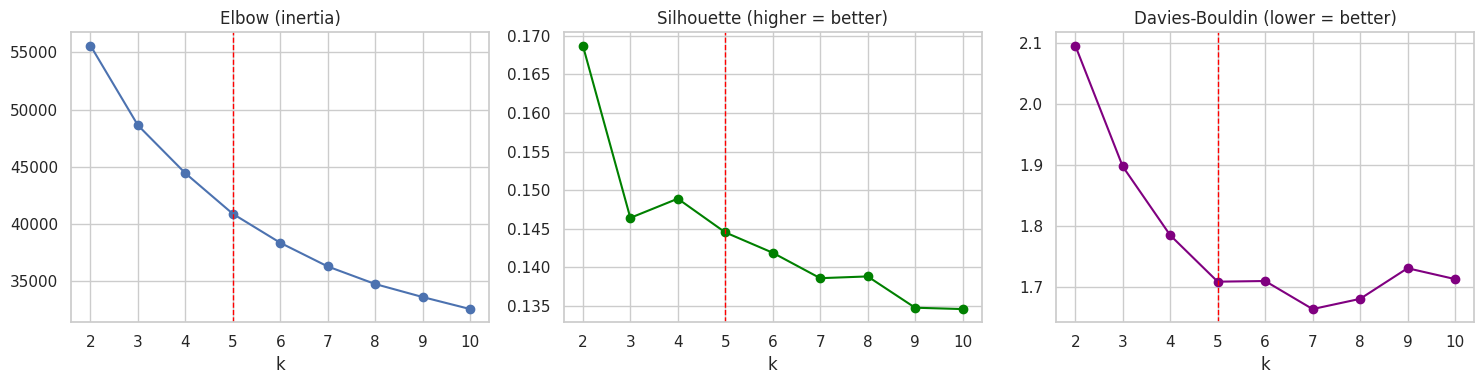

In [17]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Zs)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(Zs, km.labels_),
                 "davies_bouldin": davies_bouldin_score(Zs, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(Zs, km.labels_)})
k_table = pd.DataFrame(rows)
display(k_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o"); axes[0].set_title("Elbow (inertia)")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="green"); axes[1].set_title("Silhouette (higher = better)")
axes[2].plot(k_table["k"], k_table["davies_bouldin"], marker="o", color="purple"); axes[2].set_title("Davies-Bouldin (lower = better)")
for ax in axes: ax.axvline(K_FINAL, color="red", ls="--", lw=1); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

**Choice of k = 5.** Silhouette is highest for k = 2 but then stays almost flat (about 0.14 to 0.15) for k = 3 to 6, so the metric alone cannot decide. With k = 2 the groups are too coarse; k = 4, 5 and 6 were profiled and **k = 5 gave clearly different, meaningful segments** with a good Davies-Bouldin score. This is a judgement call and it is stated as one.

### 6.2 K-Means (fitted on all borrowers)

In [18]:
def order_labels_by(labels, values):
    """Renumber clusters 0..k-1 by ascending median of `values` (here: FICO)."""
    medians = pd.Series(values).groupby(labels).median().sort_values()
    old_to_new = np.zeros(len(medians), dtype=int)
    for new_id, old_id in enumerate(medians.index):
        old_to_new[old_id] = new_id
    return old_to_new[labels], old_to_new

kmeans = KMeans(n_clusters=K_FINAL, n_init=5, random_state=RANDOM_STATE).fit(Z)
df["kmeans_cluster"], old_to_new = order_labels_by(kmeans.labels_, df["fico_n"].values)
sample["kmeans_cluster"] = df["kmeans_cluster"].values[sample_idx]
print(df["kmeans_cluster"].value_counts().sort_index())

kmeans_cluster
0    321694
1    314600
2    292625
3    278497
4    139216
Name: count, dtype: int64


### 6.3 Hierarchical clustering (Ward linkage)

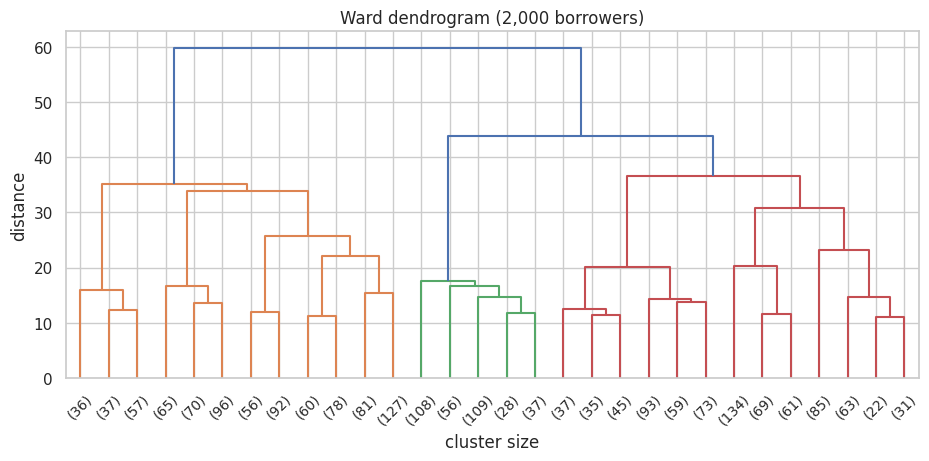

In [19]:
hier_raw = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(Zs)
sample["hier_cluster"], _ = order_labels_by(hier_raw, sample["fico_n"].values)

link = linkage(Zs[:2000], method="ward")             # dendrogram on a 2,000 subset (readable)
plt.figure(figsize=(11, 4.5))
dendrogram(link, truncate_mode="lastp", p=30, color_threshold=None)
plt.title("Ward dendrogram (2,000 borrowers)"); plt.xlabel("cluster size"); plt.ylabel("distance"); plt.show()

### 6.4 DBSCAN

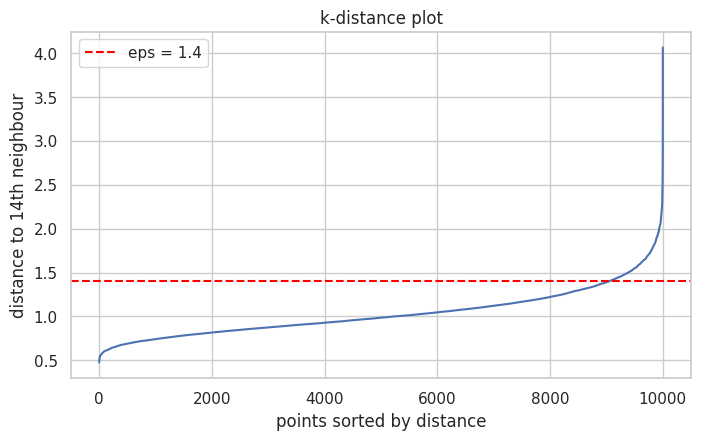

,eps,clusters,noise_pct,silhouette
0,0.6,8,95.95,0.141
1,0.8,7,60.89,-0.112
2,1.0,2,22.80,0.204
3,1.2,1,7.46,NaN
4,1.4,1,2.19,NaN
5,1.6,1,0.55,NaN


dbscan_cluster
 0    9781
-1     219
Name: count, dtype: int64


In [20]:
MIN_SAMPLES = 2 * n_keep          # rule of thumb: 2 x number of dimensions
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Zs).kneighbors(Zs)
kdist = np.sort(dist[:, -1])
EPS = 1.4                         # near the 'knee' of the k-distance curve
plt.figure(figsize=(8, 4.5)); plt.plot(kdist); plt.axhline(EPS, color="red", ls="--", label=f"eps = {EPS}")
plt.xlabel("points sorted by distance"); plt.ylabel(f"distance to {MIN_SAMPLES}th neighbour")
plt.title("k-distance plot"); plt.legend(); plt.show()

def eval_labels(Zdata, labels):
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    if n_cl < 2:
        return dict(n_clusters=n_cl, silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(n_clusters=n_cl, silhouette=silhouette_score(Zdata[mask], labels[mask]),
                davies_bouldin=davies_bouldin_score(Zdata[mask], labels[mask]),
                calinski_harabasz=calinski_harabasz_score(Zdata[mask], labels[mask]))

# how sensitive is DBSCAN to eps?
grid = []
for e in (0.6, 0.8, 1.0, 1.2, 1.4, 1.6):
    lab = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(Zs)
    m = eval_labels(Zs, lab)
    grid.append({"eps": e, "clusters": m["n_clusters"], "noise_pct": (lab == -1).mean() * 100,
                 "silhouette": m["silhouette"]})
display(pd.DataFrame(grid).round(3))

sample["dbscan_cluster"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Zs)
print(sample["dbscan_cluster"].value_counts())

DBSCAN finds **one dense region plus a few % noise**. A small eps marks most borrowers as noise; a large eps merges everything. Borrower data forms a continuous cloud, not separated islands, so DBSCAN is not good at defining segments here - but its noise points are useful as **anomalies** (section 10).

### 6.5 Algorithm comparison

In [21]:
rows = []
for name, labels in [("K-Means", sample["kmeans_cluster"].values),
                     ("Hierarchical (Ward)", sample["hier_cluster"].values),
                     ("DBSCAN", sample["dbscan_cluster"].values)]:
    m = eval_labels(Zs, labels)
    m.update({"algorithm": name, "noise_pct": (labels == -1).mean() * 100,
              "ARI_vs_kmeans": adjusted_rand_score(sample["kmeans_cluster"], labels)})
    rows.append(m)
comparison = pd.DataFrame(rows)[["algorithm", "n_clusters", "noise_pct", "silhouette",
                                 "davies_bouldin", "calinski_harabasz", "ARI_vs_kmeans"]]
comparison.round(3)

,algorithm,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_kmeans
0,K-Means,5,0.00,0.145,1.701,1586.425,1.000
1,Hierarchical (Ward),5,0.00,0.068,2.311,941.063,0.235
2,DBSCAN,1,2.19,NaN,NaN,NaN,0.008


**K-Means** has the best silhouette (0.145 vs 0.068) and Davies-Bouldin, and gives the most interpretable segments, so it is the final model. Silhouette scores are low for all methods: real borrowers change gradually, so segments overlap.

## 7. Dimensionality reduction maps (PCA, t-SNE, UMAP)

In [22]:
sample["pca_1"], sample["pca_2"] = Zs[:, 0], Zs[:, 1]

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
emb = tsne.fit_transform(Zs)
sample["tsne_1"], sample["tsne_2"] = emb[:, 0], emb[:, 1]

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=RANDOM_STATE)
emb = reducer.fit_transform(Zs)
sample["umap_1"], sample["umap_2"] = emb[:, 0], emb[:, 1]
print("done")

done


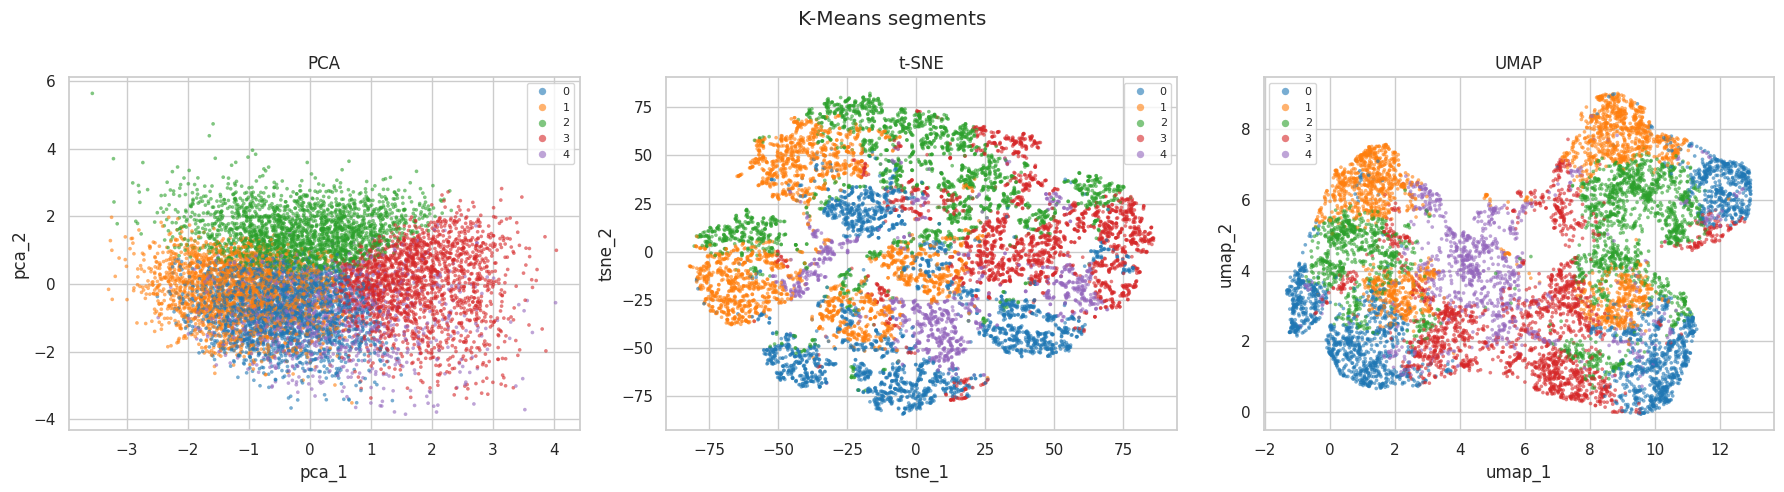

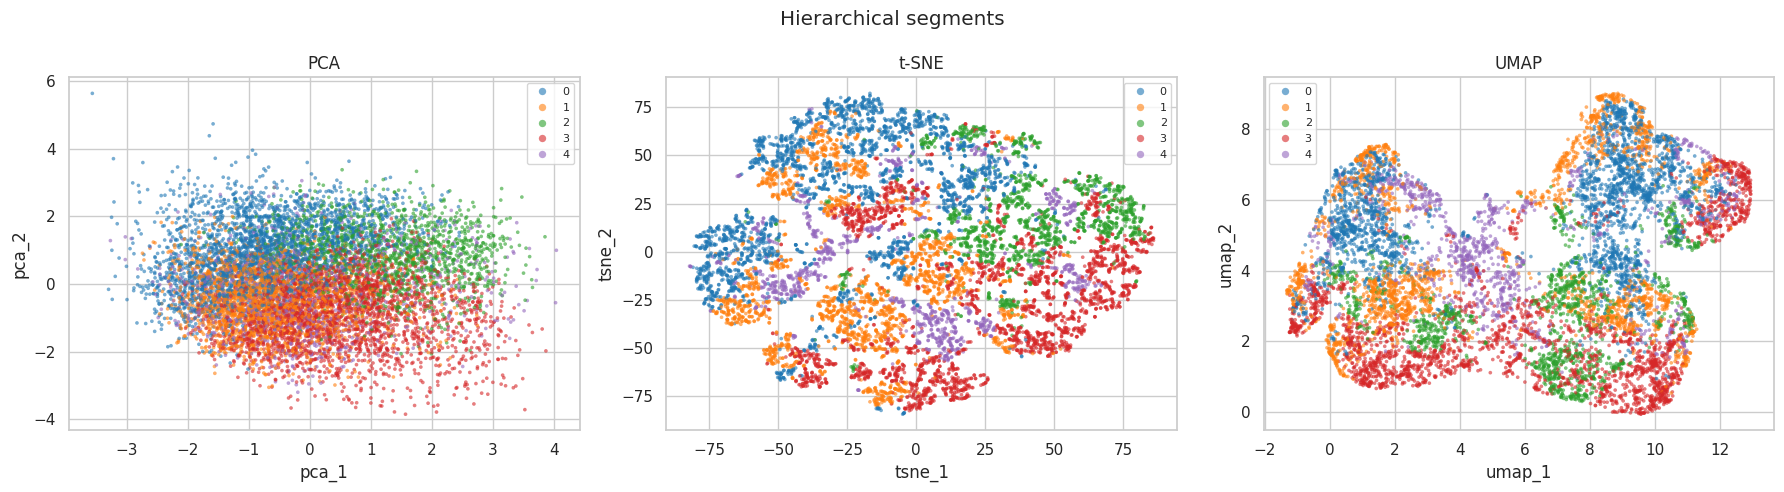

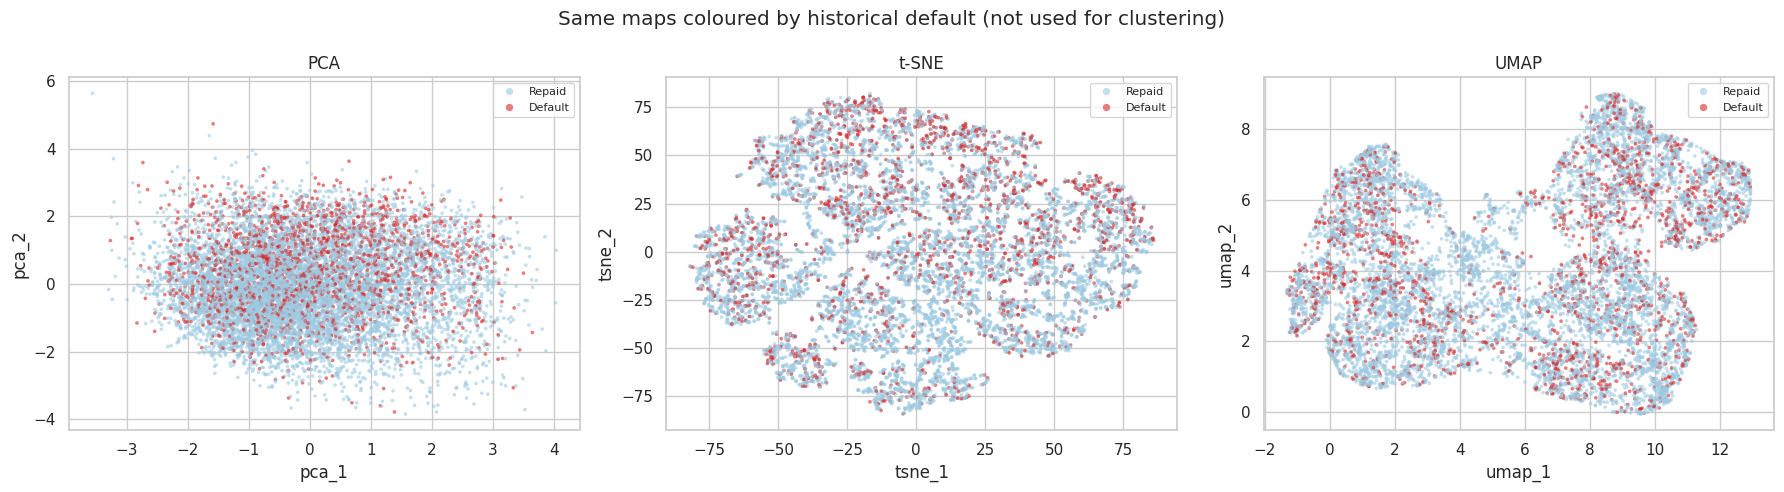

In [23]:
def three_maps(color_col, title, palette):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (x, y, name) in zip(axes, [("pca_1", "pca_2", "PCA"), ("tsne_1", "tsne_2", "t-SNE"), ("umap_1", "umap_2", "UMAP")]):
        sns.scatterplot(data=sample, x=x, y=y, hue=color_col, palette=palette, s=7, alpha=0.6, linewidth=0, ax=ax)
        ax.set_title(name); ax.legend(markerscale=2, fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

three_maps("kmeans_cluster", "K-Means segments", sns.color_palette("tab10", 5))
three_maps("hier_cluster", "Hierarchical segments", sns.color_palette("tab10", 5))
sample["Outcome"] = sample["Default"].map({0: "Repaid", 1: "Default"})
three_maps("Outcome", "Same maps coloured by historical default (not used for clustering)",
           {"Repaid": "#9ecae1", "Default": "#d62728"})

The segments occupy different regions but overlap at the edges. Defaults are spread over the whole map - segment membership shifts risk, it does not decide it.

## 8. Cluster profiling

In [24]:
g = df.groupby("kmeans_cluster")
profile = pd.DataFrame({
    "borrowers": g.size(),
    "share_pct": g.size() / len(df) * 100,
    "median_income": g["revenue"].median(),
    "median_dti": g["dti_n"].median(),
    "median_loan_amnt": g["loan_amnt"].median(),
    "median_fico": g["fico_n"].median(),
    "mean_emp_years": g["emp_years"].mean(),
    "median_loan_to_income": g["loan_to_income"].median(),
    "pct_rent": g["home_ownership_n"].apply(lambda s: (s == "RENT").mean() * 100),
    "pct_mortgage": g["home_ownership_n"].apply(lambda s: (s == "MORTGAGE").mean() * 100),
    "pct_own": g["home_ownership_n"].apply(lambda s: (s == "OWN").mean() * 100),
    "pct_debt_consolidation": g["purpose"].apply(lambda s: (s == "debt_consolidation").mean() * 100),
    "pct_credit_card": g["purpose"].apply(lambda s: (s == "credit_card").mean() * 100),
    "pct_home_improvement": g["purpose"].apply(lambda s: (s == "home_improvement").mean() * 100),
})
profile.round(2).T

kmeans_cluster,0,1,2,3,4
borrowers,321694.00,314600.00,292625.00,278497.00,139216.00
share_pct,23.89,23.36,21.73,20.68,10.34
median_income,72000.00,58000.00,43000.00,100000.00,75000.00
median_dti,16.58,14.87,24.69,17.26,13.49
median_loan_amnt,9600.00,8000.00,14175.00,26400.00,12000.00
median_fico,682.00,682.00,687.00,697.00,762.00
mean_emp_years,9.07,2.40,5.67,6.68,6.04
median_loan_to_income,0.13,0.14,0.32,0.26,0.16
pct_rent,29.99,59.07,51.11,23.23,27.91
pct_mortgage,59.97,31.65,34.75,67.72,59.95


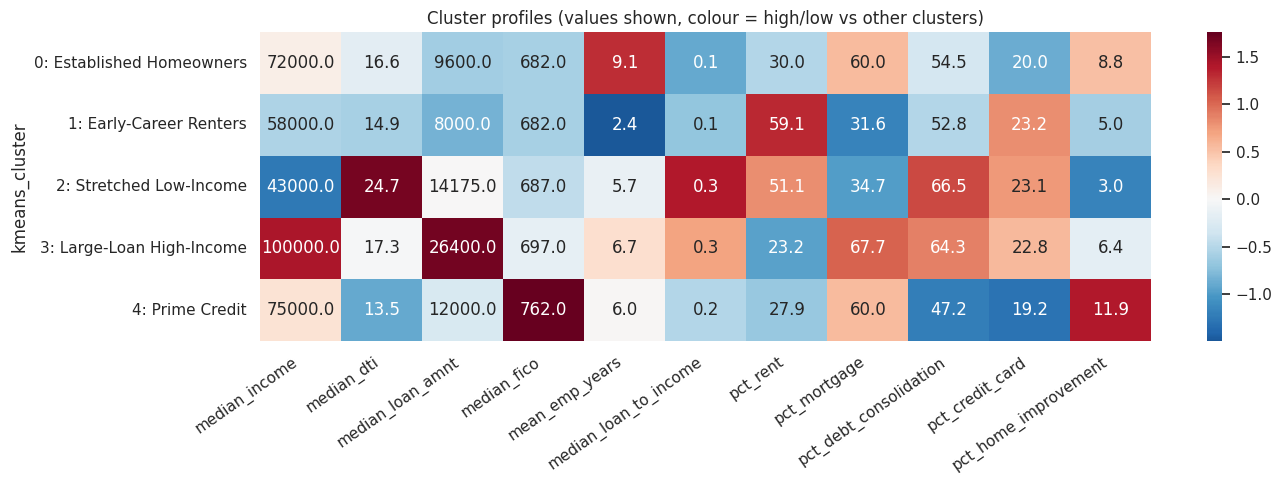

In [25]:
# descriptive names given AFTER looking at the profiles above
CLUSTER_NAMES = {0: "Established Homeowners", 1: "Early-Career Renters", 2: "Stretched Low-Income",
                 3: "Large-Loan High-Income", 4: "Prime Credit"}
cols = ["median_income", "median_dti", "median_loan_amnt", "median_fico", "mean_emp_years",
        "median_loan_to_income", "pct_rent", "pct_mortgage", "pct_debt_consolidation",
        "pct_credit_card", "pct_home_improvement"]
zscores = (profile[cols] - profile[cols].mean()) / profile[cols].std()
plt.figure(figsize=(14, 5))
sns.heatmap(zscores, annot=profile[cols].round(1), fmt="", cmap="RdBu_r", center=0,
            yticklabels=[f"{i}: {CLUSTER_NAMES[i]}" for i in profile.index])
plt.xticks(rotation=35, ha="right"); plt.title("Cluster profiles (values shown, colour = high/low vs other clusters)")
plt.tight_layout(); plt.show()

**Segments**
* **0 Established Homeowners** - long employment (9 yrs), 60% mortgage, small loans.
* **1 Early-Career Renters** - shortest employment (2.4 yrs), 59% renters, smallest loans.
* **2 Stretched Low-Income** - lowest income, highest DTI and loan-to-income, mostly debt consolidation.
* **3 Large-Loan High-Income** - highest income and biggest loans.
* **4 Prime Credit** - very high FICO (about 762), lowest DTI.

## 9. Default pattern analysis
Now (and only now) we use `Default`: it was **not** used to form the clusters.

,segment,borrowers,defaults,default_rate_pct,ci_low_pct,ci_high_pct,lift_vs_portfolio
kmeans_cluster,,,,,,,
0,Established Homeowners,321694,53636,16.67,16.54,16.80,0.83
1,Early-Career Renters,314600,57058,18.14,18.00,18.27,0.91
2,Stretched Low-Income,292625,85106,29.08,28.92,29.25,1.46
3,Large-Loan High-Income,278497,61534,22.10,21.94,22.25,1.11
4,Prime Credit,139216,11670,8.38,8.24,8.53,0.42


chi2 = 30,533, dof = 4, p = 0, Cramer's V = 0.15


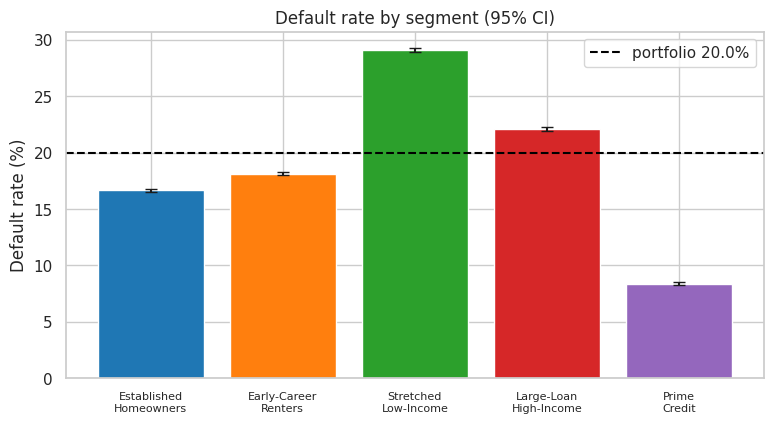

In [26]:
def wilson_ci(defaults, n, z=1.96):
    p = defaults / n
    centre = (p + z**2 / (2*n)) / (1 + z**2 / n)
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

dtab = df.groupby("kmeans_cluster")["Default"].agg(borrowers="size", defaults="sum")
dtab["default_rate_pct"] = dtab["defaults"] / dtab["borrowers"] * 100
lo, hi = wilson_ci(dtab["defaults"], dtab["borrowers"])
dtab["ci_low_pct"], dtab["ci_high_pct"] = lo * 100, hi * 100
dtab["lift_vs_portfolio"] = dtab["default_rate_pct"] / overall
dtab.insert(0, "segment", [CLUSTER_NAMES[i] for i in dtab.index])
display(dtab.round(2))

# chi-square test + effect size
table = pd.crosstab(df["kmeans_cluster"], df["Default"])
chi2, p, dof, _ = chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"chi2 = {chi2:,.0f}, dof = {dof}, p = {p:.3g}, Cramer's V = {cramers_v:.2f}")

err = [dtab["default_rate_pct"] - dtab["ci_low_pct"], dtab["ci_high_pct"] - dtab["default_rate_pct"]]
plt.figure(figsize=(9, 4.5))
plt.bar(range(5), dtab["default_rate_pct"], yerr=err, capsize=4, color=sns.color_palette("tab10", 5))
plt.axhline(overall, color="black", ls="--", label=f"portfolio {overall:.1f}%")
plt.xticks(range(5), [CLUSTER_NAMES[i].replace(" ", "\n", 1) for i in range(5)], fontsize=8)
plt.ylabel("Default rate (%)"); plt.title("Default rate by segment (95% CI)"); plt.legend(); plt.show()

With 1.3 million loans even small differences are 'significant', so the **size** of the gap matters more than the p-value: Cramer's V is about 0.15 (a small-to-moderate effect), but the rate itself goes from about 8% to 29%.

kmeans_cluster,Established Homeowners,Early-Career Renters,Stretched Low-Income,Large-Loan High-Income,Prime Credit
issue_year,,,,,
2007,NaN,24.0,NaN,NaN,NaN
2008,25.7,18.7,28.6,NaN,11.3
2009,16.5,13.5,19.4,20.8,8.8
2010,16.8,14.8,20.1,16.0,7.5
2011,15.3,15.6,22.9,20.4,7.8
2012,14.0,14.6,22.5,19.4,7.7
2013,12.6,13.8,22.2,17.1,6.2
2014,15.0,16.0,26.9,19.5,7.4
2015,16.5,17.4,29.2,21.6,7.6


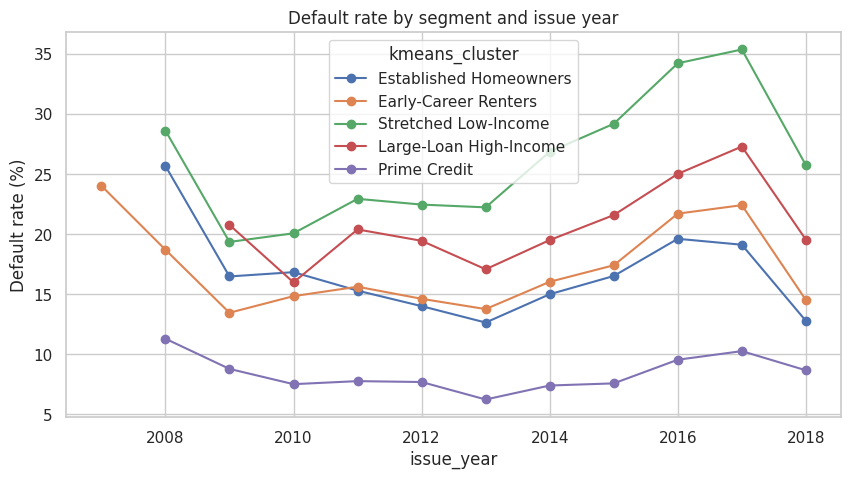

In [27]:
# does the ranking hold in every year? (only years with >= 200 loans per segment)
cnt = df.groupby(["issue_year", "kmeans_cluster"]).size().unstack()
by_year = (df.groupby(["issue_year", "kmeans_cluster"])["Default"].mean().unstack() * 100).where(cnt >= 200)
display(by_year.rename(columns=CLUSTER_NAMES).round(1))
by_year.rename(columns=CLUSTER_NAMES).plot(marker="o", figsize=(10, 5))
plt.ylabel("Default rate (%)"); plt.title("Default rate by segment and issue year"); plt.show()

*Prime Credit* has the lowest default rate in every year from 2008 to 2018, and *Stretched Low-Income* the highest in every year from 2010 to 2018 (in 2009 it was slightly below Large-Loan High-Income).

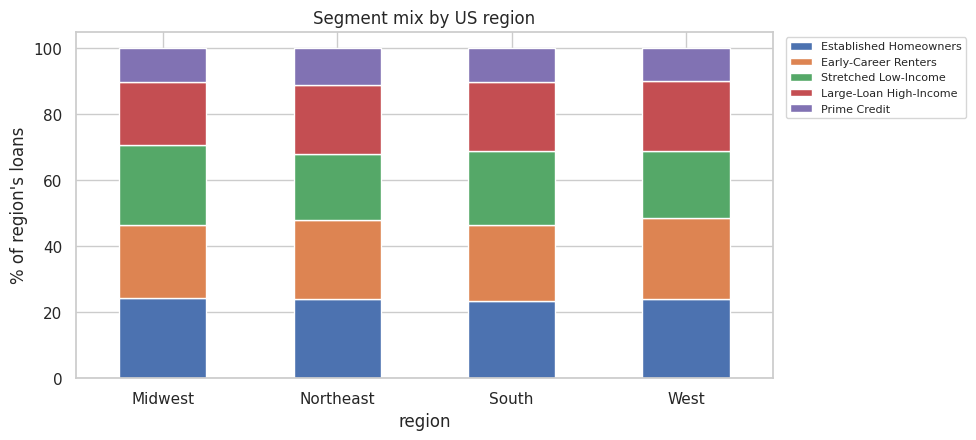

kmeans_cluster,Established Homeowners,Early-Career Renters,Stretched Low-Income,Large-Loan High-Income,Prime Credit
purpose,,,,,
car,13.2,15.7,27.0,25.1,6.5
credit_card,14.2,14.8,25.6,17.5,5.9
debt_consolidation,17.2,18.8,29.7,22.7,8.1
educational,19.6,22.9,20.8,50.0,13.1
home_improvement,15.9,17.7,29.7,23.7,8.1
house,20.0,22.3,34.3,25.4,10.7
major_purchase,15.1,17.6,32.8,30.6,10.1
medical,20.2,22.4,34.9,29.3,12.1
moving,22.2,22.8,40.5,32.9,12.2


In [28]:
# segment mix by region (geographic view) and default by purpose
mix = pd.crosstab(df["region"], df["kmeans_cluster"], normalize="index") * 100
mix.rename(columns=CLUSTER_NAMES).plot.bar(stacked=True, figsize=(9, 4.5))
plt.ylabel("% of region's loans"); plt.title("Segment mix by US region"); plt.xticks(rotation=0)
plt.legend(fontsize=8, bbox_to_anchor=(1.01, 1)); plt.show()
(df.groupby(["purpose", "kmeans_cluster"])["Default"].mean().unstack() * 100).rename(columns=CLUSTER_NAMES).round(1)

## 10. Anomaly detection
Borrowers that DBSCAN could not place in any dense group (**noise points**) are candidate anomalies. Feature-level z-scores show *what* is unusual about them.

Anomalies: 219 of 10000 (2.2%)
Default rate - anomalies: 17.8% | others: 20.2%
Share with a feature beyond 3 std - anomalies: 44.3% | others: 1.3%


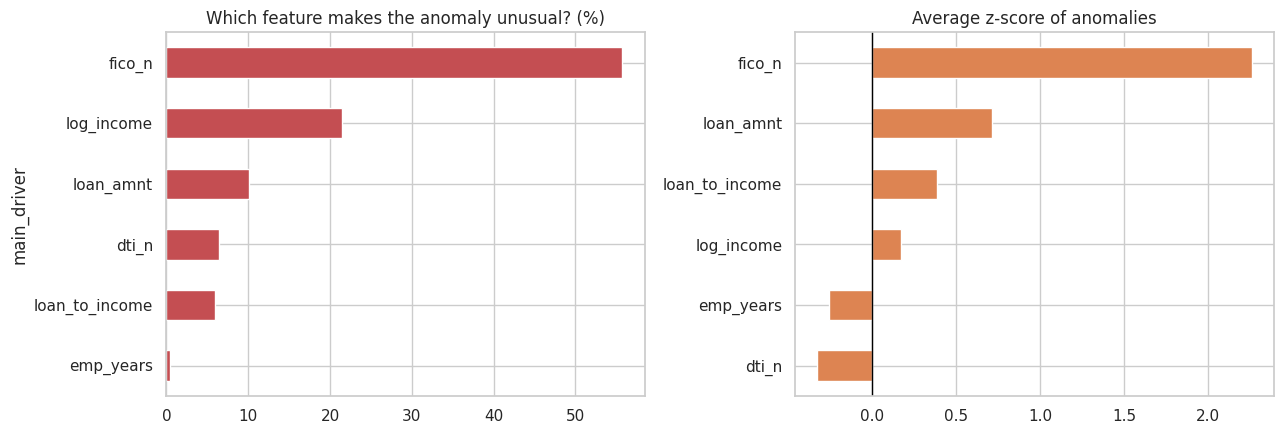

,revenue,dti_n,loan_amnt,fico_n,emp_length,purpose,home_ownership_n,kmeans_cluster,Default,main_driver
1,30000.0,2.12,2500,787.0,8 years,other,RENT,4,0,fico_n
23,109230.0,17.17,35000,787.0,3 years,house,RENT,4,0,fico_n
31,100000.0,9.17,35000,822.0,NI,debt_consolidation,MORTGAGE,4,0,fico_n
127,70000.0,17.74,31300,767.0,3 years,credit_card,RENT,3,0,fico_n
128,104000.0,32.42,40000,782.0,10+ years,debt_consolidation,MORTGAGE,3,0,loan_amnt
156,79000.0,20.43,30000,782.0,2 years,other,MORTGAGE,4,0,fico_n
177,31000.0,9.52,9600,767.0,7 years,debt_consolidation,RENT,4,0,fico_n
398,28000.0,14.44,2300,757.0,10+ years,credit_card,OWN,4,0,fico_n
407,40000.0,32.44,3000,817.0,10+ years,debt_consolidation,OWN,4,0,fico_n
497,8508.0,30.32,2500,737.0,NI,debt_consolidation,RENT,2,1,log_income


In [29]:
scaler = preprocessor.named_transformers_["num"]
z = pd.DataFrame((sample[NUMERIC_FEATURES].values - scaler.mean_) / scaler.scale_, columns=NUMERIC_FEATURES)
sample["is_anomaly"] = (sample["dbscan_cluster"] == -1).astype(int)
sample["main_driver"] = z.abs().idxmax(axis=1)
sample["max_abs_z"] = z.abs().max(axis=1).values
sample["n_extreme_features"] = (z.abs() > 3).sum(axis=1).values   # features beyond 3 std

anom = sample[sample["is_anomaly"] == 1]
normal = sample[sample["is_anomaly"] == 0]
print(f"Anomalies: {len(anom)} of {len(sample)} ({len(anom)/len(sample):.1%})")
print(f"Default rate - anomalies: {anom['Default'].mean():.1%} | others: {normal['Default'].mean():.1%}")
print(f"Share with a feature beyond 3 std - anomalies: {(anom['n_extreme_features']>0).mean():.1%} | others: {(normal['n_extreme_features']>0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
anom["main_driver"].value_counts(normalize=True).mul(100).sort_values().plot.barh(ax=axes[0], color="#C44E52")
axes[0].set_title("Which feature makes the anomaly unusual? (%)")
z.loc[anom.index].mean().sort_values().plot.barh(ax=axes[1], color="#DD8452")
axes[1].axvline(0, color="black", lw=1); axes[1].set_title("Average z-score of anomalies")
plt.tight_layout(); plt.show()

anom[["revenue", "dti_n", "loan_amnt", "fico_n", "emp_length", "purpose", "home_ownership_n",
      "kmeans_cluster", "Default", "main_driver"]].head(10)

Anomalies are mostly **unusually high FICO scores or incomes**; their default rate is *not* higher than normal. They are unusual, not necessarily risky - they should go to an analyst for review, not be rejected automatically.

## 11. Save the model with pickle and export files for the dashboard

In [30]:
import os, pickle
os.makedirs("models", exist_ok=True)

# Everything needed to put a NEW borrower into a segment is stored in one dictionary
model_bundle = {
    "caps": caps,                         # outlier limits
    "emp_length_map": EMP_MAP,            # '5 years' -> 5
    "preprocessor": preprocessor,         # scaler + one-hot encoder
    "pca": pca,                           # PCA (7 components)
    "kmeans": kmeans,                     # the trained K-Means model
    "label_map": old_to_new,              # K-Means id -> id ordered by FICO
    "feature_columns": feature_cols,
    "cluster_names": CLUSTER_NAMES,
}
with open("models/model.pkl", "wb") as f:
    pickle.dump(model_bundle, f)
print("Saved models/model.pkl")

Saved models/model.pkl


In [31]:
# Load the model back from the pickle file and use it on a brand-new borrower
with open("models/model.pkl", "rb") as f:
    loaded = pickle.load(f)

def predict_segment(person, bundle):
    """Return the segment name for one borrower (a dict of raw values)."""
    row = pd.DataFrame([person])
    row["emp_years"] = bundle["emp_length_map"].get(person.get("emp_length"), np.nan)
    row = engineer_features(row, bundle["caps"])
    z_new = bundle["pca"].transform(bundle["preprocessor"].transform(row[bundle["feature_columns"]]))
    seg_id = int(bundle["label_map"][bundle["kmeans"].predict(z_new)[0]])
    return seg_id, bundle["cluster_names"][seg_id]

example = {"revenue": 65000, "dti_n": 17, "loan_amnt": 12000, "fico_n": 780,
           "emp_length": "5 years", "purpose": "credit_card", "home_ownership_n": "MORTGAGE"}
print(predict_segment(example, loaded))

# sanity check: the loaded model reproduces the labels we got during training
test = sample.head(2000)
ok = [predict_segment({"revenue": r.revenue, "dti_n": r.dti_n, "loan_amnt": r.loan_amnt, "fico_n": r.fico_n,
                       "emp_length": r.emp_length, "purpose": r.purpose,
                       "home_ownership_n": r.home_ownership_n}, loaded)[0] == r.kmeans_cluster
      for r in test.itertuples()]
print("Agreement with training labels:", np.mean(ok))

(4, 'Prime Credit')


Agreement with training labels: 1.0


In [32]:
# Export the small files that the Streamlit dashboard reads
os.makedirs("data/processed", exist_ok=True)

sample["cluster_name"] = sample["kmeans_cluster"].map(CLUSTER_NAMES)
keep = ["issue_year", "revenue", "dti_n", "loan_amnt", "fico_n", "emp_years", "emp_length",
        "purpose", "home_ownership_n", "addr_state", "region", "loan_to_income", "Default",
        "kmeans_cluster", "hier_cluster", "dbscan_cluster", "is_anomaly", "max_abs_z",
        "main_driver", "pca_1", "pca_2", "tsne_1", "tsne_2", "umap_1", "umap_2", "cluster_name"]
sample[keep].round(4).to_csv("data/processed/dashboard_sample.csv", index=False)

summary = profile.copy()                              # profile of every segment (all borrowers)
summary["defaults"] = dtab["defaults"]
summary["default_rate_pct"] = dtab["default_rate_pct"]
summary["ci_low_pct"], summary["ci_high_pct"] = dtab["ci_low_pct"], dtab["ci_high_pct"]
summary.insert(0, "segment", [CLUSTER_NAMES[i] for i in summary.index])
summary.round(3).to_csv("data/processed/app_cluster_summary.csv", index=False)

by_year.rename(columns=CLUSTER_NAMES).round(2).to_csv("data/processed/app_default_by_year.csv")
comparison.round(3).to_csv("data/processed/app_algorithm_comparison.csv", index=False)
print("Exported dashboard files to data/processed/")

Exported dashboard files to data/processed/


### Conclusions
* K-Means with **k = 5** found five interpretable borrower segments; default rates range from **8.4% (Prime Credit) to 29.1% (Stretched Low-Income)** against a 20.0% portfolio average - about 3.5x - even though `Default` was never used for clustering.
* **K-Means** beat Hierarchical clustering (silhouette 0.145 vs 0.068); **DBSCAN** found one dense cloud plus about 2% noise and is best used for anomaly detection.
* Credit score separates risk best, but **affordability** (DTI, loan-to-income) matters as much: Stretched Low-Income borrowers have an average-looking FICO yet the highest default rate.
* Anomalies are mostly unusually high FICO or income, not riskier borrowers.

### Limitations
* Low silhouette (about 0.15): segments overlap and are tendencies, not hard boundaries.
* Loans from 2017-2018 had less time to default, so their rates are understated.
* Only 8 borrower variables; no payment history or macro-economic data.
* Hierarchical, DBSCAN, t-SNE and UMAP used a 10,000-borrower sample.
* Cluster membership describes a **group** and must not be used alone to judge an individual borrower.

### Next steps
The dashboard files are already exported by the last code cell. Start the dashboard with `streamlit run app.py`.